# Analiza streszczeń literatury młodziezowej

## Import bibliotek

In [75]:
import nltk
from nltk.corpus import PlaintextCorpusReader
from nltk.tokenize import word_tokenize
from nltk.util import ngrams
import json
import os
import string
import operator as op
import itertools as it
import morfeusz2
import pandas as pd
import numpy as np
import sklearn
from wordcloud import WordCloud
from matplotlib import pyplot as plt
from matplotlib.colors import to_hex
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from scipy.cluster.hierarchy import dendrogram
from sklearn.cluster import AgglomerativeClustering
from sklearn.decomposition import LatentDirichletAllocation, NMF
from sklearn.metrics.pairwise import cosine_similarity, euclidean_distances
corpus_dir = os.path.abspath("./Literature")

In [41]:
import ssl

try:
    _create_unverified_https_context = ssl._create_unverified_context
except AttributeError:
    pass
else:
    ssl._create_default_https_context = _create_unverified_https_context

nltk.download('punkt_tab')

[nltk_data] Downloading package punkt_tab to
[nltk_data]     /Users/weronikagurba/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

In [42]:
nltk.pathsec.ENFORCE = False

## Zdefiniowanie funkcji pomocniczych

In [43]:
def print_dict(obj):
    print(json.dumps(obj, indent=4, ensure_ascii=False))

In [44]:
def create_dir(path):
    if not os.path.exists(path):
        os.mkdir(path)

## Utworzenie korpusu dokumentów

In [45]:
corpus_dir = "./Literature"
corpus = PlaintextCorpusReader(corpus_dir, r".*\.txt")
files_names = corpus.fileids()

In [46]:
document_dict = {}
for file_name in files_names:
    document_dict[file_name] = corpus.raw(file_name)
print(json.dumps(document_dict, indent=4, ensure_ascii=False)) 

{
    "Harry Potter i Czara Ognia.txt": "Lord Voldemort, wraz ze swoim sługą Glizdogonem przybywa do domu należącego niegdyś do rodziny Riddle'ów położonego w Little Hangleton. Tam układają plan dotyczący zamordowania Harry'ego Pottera, co ma pomóc Czarnemu Panu w odzyskaniu jego dawnej mocy. Jest także mowa o wiernym słudze Czarnego Pana, który wkrótce ma znaleźć się w Hogwarcie. Wszystko to słyszy mieszkający nieopodal ogrodnik, Frank Bryce. Voldemort odkrywając, iż mężczyzna podsłuchuje, zaprasza go do środka i uśmierca. Harry budzi się z przerażającego snu. Jego blizna pulsuje okropnym bólem. Próbuje sobie przypomnieć o czym śnił, a z pamięci wyłania się obraz mrocznego pokoju, węża leżącego przed kominkiem oraz Glizdogona i Lorda Voldemorta planujących morderstwo. Harry zastanawia się czy powinien komuś powiedzieć o problemach z blizną, ponieważ, gdy bolała go ostatnim razem, Voldemort wdarł się do Hogwartu. Ostatecznie postanawia napisać do Syriusza i zejść na śniadanie. W trakci

/Users/weronikagurba/Desktop/projekty/TextMining/.venv/lib/python3.13/site-packages/nltk/corpus/reader/api.py:231: RuntimeWarning: Security Warning [CorpusReader]: Path /Users/weronikagurba/Desktop/projekty/TextMining/Literature/Harry Potter i Czara Ognia.txt allowed via CWD.
  with self.open(f) as fp:
/Users/weronikagurba/Desktop/projekty/TextMining/.venv/lib/python3.13/site-packages/nltk/data.py:444: RuntimeWarning: Security Warning [pathsec.open]: Path /Users/weronikagurba/Desktop/projekty/TextMining/Literature/Harry Potter i Czara Ognia.txt allowed via CWD.
  stream = _secure_open(self._path, "rb")
/Users/weronikagurba/Desktop/projekty/TextMining/.venv/lib/python3.13/site-packages/nltk/corpus/reader/api.py:231: RuntimeWarning: Security Warning [CorpusReader]: Path /Users/weronikagurba/Desktop/projekty/TextMining/Literature/Harry Potter i Insygnia Smierci.txt allowed via CWD.
  with self.open(f) as fp:
/Users/weronikagurba/Desktop/projekty/TextMining/.venv/lib/python3.13/site-packag

In [47]:
lengths = {}
for file_name in document_dict:
    lengths[file_name] = {
        'pre': len(word_tokenize(document_dict[file_name]))
    }
    print_dict(lengths)

{
    "Harry Potter i Czara Ognia.txt": {
        "pre": 6748
    }
}
{
    "Harry Potter i Czara Ognia.txt": {
        "pre": 6748
    },
    "Harry Potter i Insygnia Smierci.txt": {
        "pre": 2997
    }
}
{
    "Harry Potter i Czara Ognia.txt": {
        "pre": 6748
    },
    "Harry Potter i Insygnia Smierci.txt": {
        "pre": 2997
    },
    "Harry Potter i Kamien Filozoficzny.txt": {
        "pre": 2236
    }
}
{
    "Harry Potter i Czara Ognia.txt": {
        "pre": 6748
    },
    "Harry Potter i Insygnia Smierci.txt": {
        "pre": 2997
    },
    "Harry Potter i Kamien Filozoficzny.txt": {
        "pre": 2236
    },
    "Harry Potter i Komnata Tajemnic.txt": {
        "pre": 1611
    }
}
{
    "Harry Potter i Czara Ognia.txt": {
        "pre": 6748
    },
    "Harry Potter i Insygnia Smierci.txt": {
        "pre": 2997
    },
    "Harry Potter i Kamien Filozoficzny.txt": {
        "pre": 2236
    },
    "Harry Potter i Komnata Tajemnic.txt": {
        "pre": 1611
 

## Utworzenie macierzy częstości

In [48]:
documents_df_pre = pd.DataFrame.from_dict(document_dict, orient='index', columns=['content'])

In [49]:
matrix_tf = CountVectorizer().fit_transform(documents_df_pre['content'])

In [50]:
sparsity_tf = (1 - (matrix_tf.nnz / (matrix_tf.shape[0] * matrix_tf.shape[1]))) * 100

In [51]:
matrices = {
    "pre": {
        "words": matrix_tf.shape[1],
        "sparsity": sparsity_tf
    }
}

## Wstępne przygotowanie dokumentów

In [52]:
stopwords_file = open("./stopwords_pl.txt", "r", encoding="UTF-8")
stopwords = stopwords_file.read().splitlines()
stopwords = stopwords[4:]
stopwords_file.close()
stopwords

['vol',
 'o.o.',
 'mgr',
 'godz',
 'zł',
 'www',
 'pl',
 'ul',
 'tel',
 'hab',
 'prof',
 'inż',
 'dr',
 'i',
 'u',
 'aby',
 'albo',
 'ale',
 'ani',
 'aż',
 'bardzo',
 'bez',
 'bo',
 'bowiem',
 'by',
 'byli',
 'bym',
 'był',
 'była',
 'było',
 'były',
 'być',
 'będzie',
 'będą',
 'chce',
 'choć',
 'co',
 'coraz',
 'coś',
 'czy',
 'czyli',
 'często',
 'dla',
 'do',
 'gdy',
 'gdyby',
 'gdyż',
 'gdzie',
 'go',
 'ich',
 'im',
 'inne',
 'iż',
 'ja',
 'jak',
 'jakie',
 'jako',
 'je',
 'jednak',
 'jednym',
 'jedynie',
 'jego',
 'jej',
 'jest',
 'jeszcze',
 'jeśli',
 'jeżeli',
 'już',
 'ją',
 'kiedy',
 'kilku',
 'kto',
 'która',
 'które',
 'którego',
 'której',
 'który',
 'których',
 'którym',
 'którzy',
 'lat',
 'lecz',
 'lub',
 'ma',
 'mają',
 'mamy',
 'mi',
 'miał',
 'mimo',
 'mnie',
 'mogą',
 'może',
 'można',
 'mu',
 'musi',
 'na',
 'nad',
 'nam',
 'nas',
 'nawet',
 'nic',
 'nich',
 'nie',
 'niej',
 'nim',
 'niż',
 'no',
 'nowe',
 'np',
 'nr',
 'o',
 'od',
 'ok',
 'on',
 'one',
 'oraz',
 '

In [53]:
def lemmatize(text):
    morfer = morfeusz2.Morfeusz()
    segments = it.groupby(morfer.analyse(text), op.itemgetter(0,1))
    def disambiguate(group):
        pairs = ((len(descr), lemma) for _, _, (_, lemma, descr, _, _, ) in group)
        perpl, lemma = min(pairs)
        return lemma.split(":")[0] if lemma else None
    lemmas = (disambiguate(group) for _, group in segments)
    return " ".join(filter(str.isalpha, lemmas))

In [54]:
for file_name in document_dict:
    document_dict[file_name] = document_dict[file_name].lower()
    document_dict[file_name] = "".join([char for char in document_dict[file_name] if char not in string.punctuation])
    document_dict[file_name] = lemmatize(document_dict[file_name])
    document_dict[file_name] = " ".join([word for word in word_tokenize(document_dict[file_name], language='polish') if word not in stopwords])
print_dict(document_dict)

{
    "Harry Potter i Czara Ognia.txt": "lord voldemort wraz sługa glizdogonem przybywać dom należący niegdyś rodzina riddleów położony little hangleton układać plan dotyczyć zamordować harryego pottera mieć pomóc czarny odzyskanie dawny moc mowa wierna sługa czarny wkrótce mieć znaleźć hogwarcie słyszeć mieszkać nieopodal ogrodnik frank bryka voldemort odkrywać mężczyzna podsłuchiwać zapraszać środek uśmiercać Harry budzić przerażający sen blizna pulsować okropny ból próbować siebie przypomnieć czym śnić a pamięć wyłaniać obraza mroczny pokój wąż leżący kominek glizdogona lord voldemorta planować morderstwo Harry zastanawiać powinien ktoś powiedzieć problem blizna boleć ostatni razem voldemort wedrzeć hogwartu ostatecznie postanawiać napisać Syriusz zejść śniadanie trakt śniadanie wuj vernon otrzymywać lista weasleyowie oferować zabrać harryego finał mistrzostwa świat quidditchu ugościć reszta wakacje długi namysł użycie harryego odpowiedni argument wuj zgadzać wyjazd pokój Harry zast

In [55]:
for file_name in document_dict:
    lengths[file_name]['post'] = len(word_tokenize(document_dict[file_name]))
print_dict(lengths)

{
    "Harry Potter i Czara Ognia.txt": {
        "pre": 6748,
        "post": 3806
    },
    "Harry Potter i Insygnia Smierci.txt": {
        "pre": 2997,
        "post": 1681
    },
    "Harry Potter i Kamien Filozoficzny.txt": {
        "pre": 2236,
        "post": 1234
    },
    "Harry Potter i Komnata Tajemnic.txt": {
        "pre": 1611,
        "post": 888
    },
    "Harry Potter i Ksiaze Polkrwi.txt": {
        "pre": 1993,
        "post": 1141
    },
    "Harry Potter i Przeklete Dziecko.txt": {
        "pre": 3170,
        "post": 1742
    },
    "Harry Potter i Wiezien Azkabanu.txt": {
        "pre": 2227,
        "post": 1241
    },
    "Harry Potter i Zakon Feniksa.txt": {
        "pre": 1821,
        "post": 1039
    },
    "Opowiesci z Narni. Kon i jego chlopiec.txt": {
        "pre": 179,
        "post": 106
    },
    "Opowiesci z Narni. Ksiaze Kaspian.txt": {
        "pre": 2376,
        "post": 1299
    },
    "Opowiesci z Narni. Lew, czarownica i stara szafa.txt"

In [56]:
lengths = pd.DataFrame.from_dict(lengths, orient='index')
lengths['change'] = lengths['post'] - lengths['pre']
lengths['change_percentage'] = ((lengths['change'] / lengths['pre']) * 100).round(2)
display(lengths)

,pre,post,change,change_percentage
Harry Potter i Czara Ognia.txt,6748,3806,-2942,-43.60
Harry Potter i Insygnia Smierci.txt,2997,1681,-1316,-43.91
Harry Potter i Kamien Filozoficzny.txt,2236,1234,-1002,-44.81
Harry Potter i Komnata Tajemnic.txt,1611,888,-723,-44.88
Harry Potter i Ksiaze Polkrwi.txt,1993,1141,-852,-42.75
Harry Potter i Przeklete Dziecko.txt,3170,1742,-1428,-45.05
Harry Potter i Wiezien Azkabanu.txt,2227,1241,-986,-44.27
Harry Potter i Zakon Feniksa.txt,1821,1039,-782,-42.94
Opowiesci z Narni. Kon i jego chlopiec.txt,179,106,-73,-40.78
Opowiesci z Narni. Ksiaze Kaspian.txt,2376,1299,-1077,-45.33


## Utworzenie macierzy częstości

In [57]:
documents_df_post = pd.DataFrame.from_dict(document_dict, orient='index', columns=['content'])

In [58]:
cv = CountVectorizer()
matrix_tf = cv.fit_transform(documents_df_post['content'])
tv = TfidfVectorizer()
matrix_tfidf = tv.fit_transform(documents_df_post['content'])

In [59]:
sparsity_tf = (1 - (matrix_tf.nnz / (matrix_tf.shape[0] * matrix_tf.shape[1]))) * 100

In [60]:
matrices["post"] = {
    "words": matrix_tf.shape[1],
    "sparsity": sparsity_tf
}

In [61]:
matrices = pd.DataFrame.from_dict(matrices, orient="index")
display(matrices)

,words,sparsity
pre,7469,90.955951
post,4675,89.312299


## Przygotowanie katalogów wyjściowych

In [62]:
create_dir("./wordclouds")
create_dir("./wordclouds/pre")
create_dir("./wordclouds/post")
create_dir("./topic_models")
create_dir("./topic_models/topics")
create_dir("./topic_models/documents")
create_dir("./clustering")
create_dir("./ngrams")

## Chmury tagów

In [63]:
wordcloud = WordCloud(
    background_color="white",
    max_words = 5000,
    contour_width=3,
    contour_color="steelblue"
)

In [64]:
for index, row in documents_df_pre.iterrows():
    wordcloud.generate(row["content"])
    plt.imshow(wordcloud, interpolation="bilinear")
    plt.axis("off")
    plt.title(index.replace(".txt", ""))
    plt.savefig(f"./wordclouds/pre/{index.replace(".txt", ".png")}")
    plt.close()


In [65]:
for index, row in documents_df_post.iterrows():
    wordcloud.generate(row["content"])
    plt.imshow(wordcloud, interpolation="bilinear")
    plt.axis("off")
    plt.title(index.replace(".txt", ""))
    plt.savefig(f"./wordclouds/post/{index.replace(".txt", ".png")}")
    plt.close()


## Analiza tematów

In [71]:
def plot_top_words(model, feature_names, n_top_words, title, subplots, colors):
    fig, axes = plt.subplots(*subplots, figsize=(30, 15), sharex=True)
    axes = axes.flatten()
    for topic_idx, topic in enumerate(model.components_):
        top_features_ind = topic.argsort()[-n_top_words:]
        top_features = feature_names[top_features_ind]
        weights = topic[top_features_ind]

        ax = axes[topic_idx]
        ax.barh(top_features, weights, height=0.7, color=colors[topic_idx])
        ax.set_title(f"Temat {topic_idx + 1}", fontdict={"fontsize": 30})
        ax.tick_params(axis="both", which="major", labelsize=20)
        for i in "top right left".split():
            ax.spines[i].set_visible(False)
        fig.suptitle(title, fontsize=40)

    plt.subplots_adjust(top=0.90, bottom=0.05, wspace=0.90, hspace=0.3)
    plt.savefig(f"./topic_models/" + str(n_components) + "/topics/" + title.replace(" ", "_") + ".png")
    plt.close()


In [ ]:
def plot_documents(model, matrix, n_components, title, colors):
    colors = ["#ED6A5A", "#C7C37C", "#9BC1BC", "#5D576B", "#E6EBE0", "#C3979F", "#3F612D", "#BDA0BC", "#B26700", "#EF798A"]
    documents_topics = pd.DataFrame(model.transform(matrix))    
    documents_topics.columns = ["Temat " + str(i) for i in range(1, n_components+1)]
    documents_topics.index = [file_name.replace(".txt", "") for file_name in files_names]
    n_docs = len(documents_topics)
    plt.figure(figsize=(7,4))
    left = [0] * n_docs
    for i, col in enumerate(documents_topics.columns):
        plt.barh(documents_topics.index, documents_topics[col], left=left, label= col, color=colors[i])
        left= [left[i] + documents_topics[col].iloc[j] for j in range(n_docs)]
    plt.savefig("./topic_models/" + str(n_components) + "/documents/" + title.replace(" ", "_") + ".png")
    plt.close()

In [73]:
colors = ["#ED6A5A", "#C7C37C", "#9BC1BC", "#5D576B", "#E6EBE0", "#C3979F", "#3F612D", "#BDA0BC", "#B26700", "#EF798A"]
feature_names = cv.get_feature_names_out()
n_top_features = 20
size = [2,3]
n_components = size[0]*size[1]

FileNotFoundError: [Errno 2] No such file or directory: './topic_models/6/topics/Tematu_w_modeli_LDA.png'

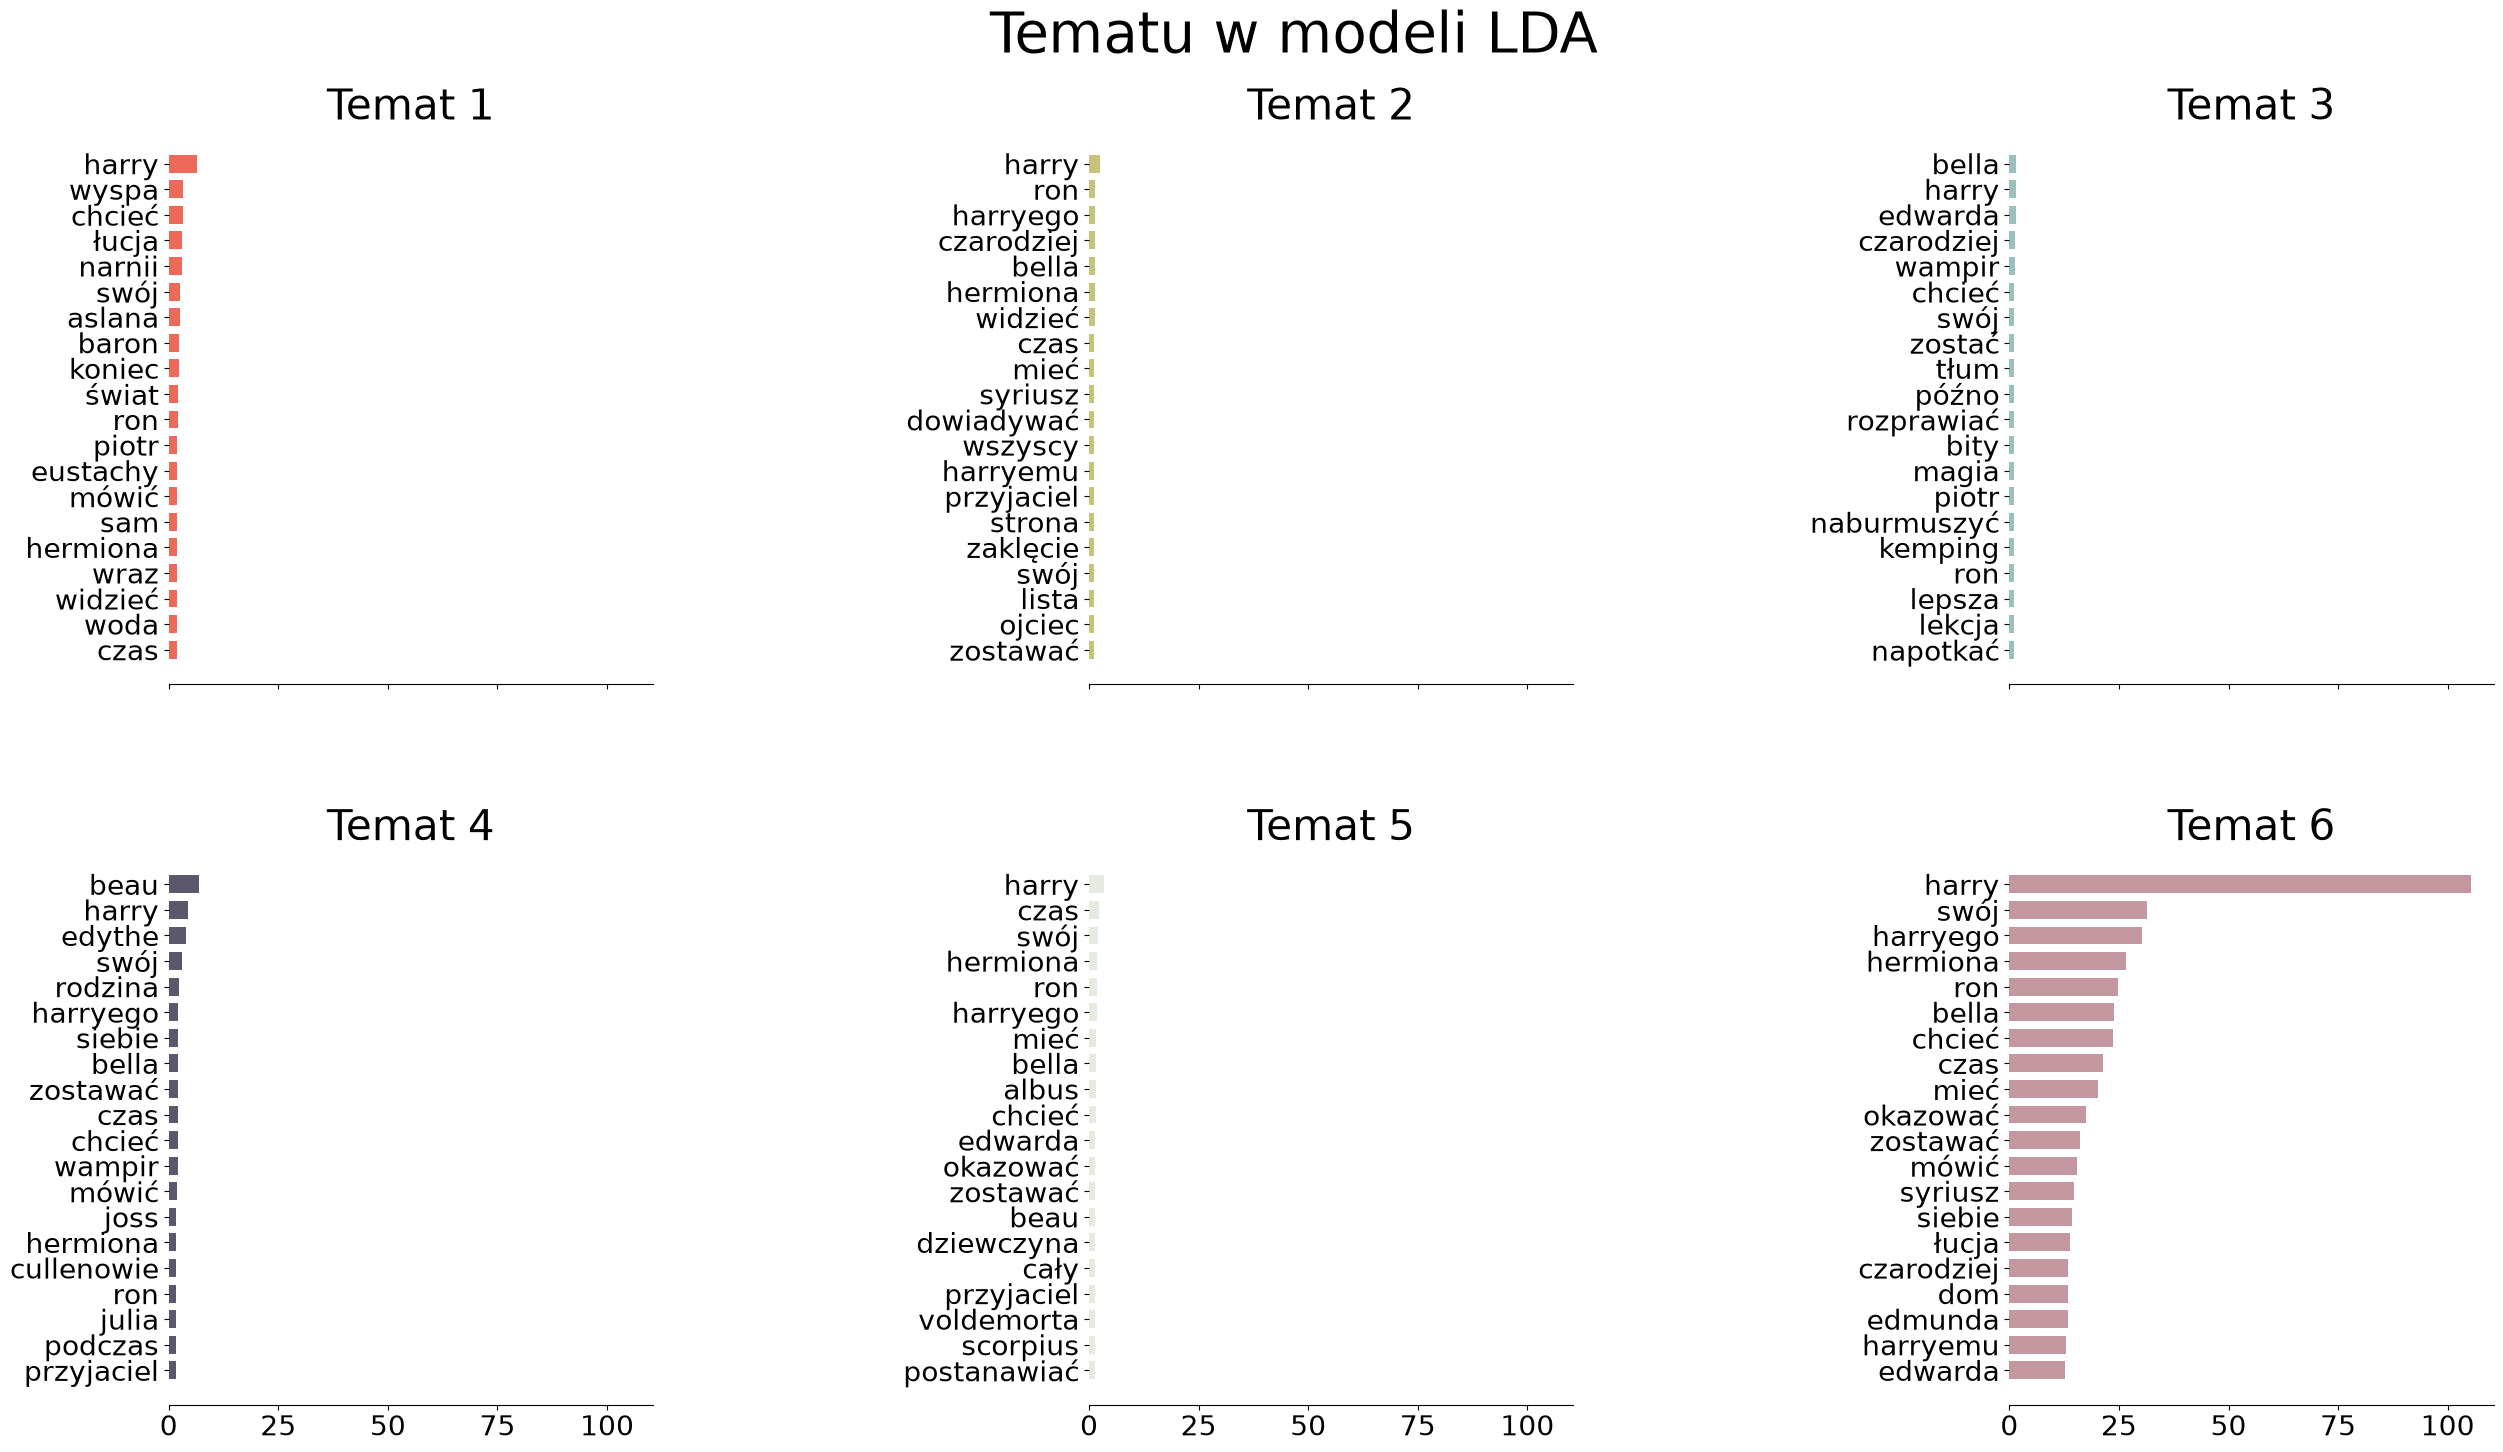

In [74]:
lda = LatentDirichletAllocation(
    n_components=n_components,
    max_iter=5,
    learning_method="online",
    learning_offset=50,
    random_state=0
)

lda.fit(matrix_tf)
plot_top_words(lda, feature_names, n_top_features, "Tematu w modeli LDA", size, colors)
plot_documents(lda, matrix_tf, n_components, "Tematu w modeli LDA", colors)

In [ ]:
nmf_fn = NMF(
    n_components=n_components,
    random_state=1,
    alpha_H=.00005,
    alpha_W=.0005,
    l1_ratio=.5
)
nmf_fn.fit(matrix_tf)
plot_top_words(nmf_fn, feature_names, n_top_features, "Tematu w modeli NMF FN", size, colors)
plot_documents(nmf_fn, matrix_tf, n_components, "Tematu w modeli NMF FN", colors)

In [ ]:
nmf_kl = NMF(
    n_components=n_components,
    random_state=1,
    beta_loss="kullback-leibler",
    solver="mu",
    alpha_H=.00005,
    alpha_W=.0005,
    l1_ratio=.5
)
nmf_kl.fit(matrix_tf)
plot_top_words(nmf_kl, feature_names, n_top_features, "Tematu w modeli NMF KL", size, colors)
plot_documents(nmf_kl, matrix_tf, n_components, "Tematu w modeli NMF KL", colors)